# 11 — Figur Paper

Notebook ini menghasilkan **seluruh figur placeholder** pada draft paper
(`main.pdf`), siap ditempel ke LaTeX. Semua angka dibaca dari artefak di
`results/` (tidak ada angka yang diketik ulang), sehingga figur selalu konsisten
dengan Tabel II–IV.

| Figur | Berkas | Isi | Sumber data |
| --- | --- | --- | --- |
| Fig. 2 | `fig_data.png` | (a) foto multi-bean + bbox Roboflow, (b) strip crop 5 kelas × 2 | `data/annotated`, `data/crops_raw` |
| Fig. 3 | `fig_curves.pdf` | (a) loss train/val, (b) val acc + marker checkpoint | `results/models/<m>/<m>_history.json` |
| Fig. 4 | `fig_perclass_f1.pdf` | F1 per kelas, bar berkelompok | `results/analysis/per_class_metrics.csv` |
| Fig. 5 | `fig_confusion.pdf` | 3 confusion matrix ternormalisasi baris | `results/analysis/<m>_test_predictions.csv` (TTA D4) |
| Fig. 6 | `fig_tta.pdf` | (a) F1, (b) miss rate: tanpa TTA vs D4 | `results/experiments/tta_screening.csv` |
| Fig. 7 | `fig_tradeoff.pdf` | F1 vs ukuran model, bubble = parameter | `results/analysis/efficiency_comparison.csv` |
| Fig. 8 | `fig_gradcam.png` | Grad-CAM: (a) benar, (b) lubang kecil → `good` | checkpoint + prediksi TTA |
| Fig. 9 | `fig_confidence.pdf` | (a) histogram confidence, (b) t-SNE fitur beku | prediksi + `<m>_test_features.npz` |

Keluaran: `results/figures/paper/` (PDF vektor + PNG 300 dpi untuk tiap figur).

**Konvensi visual.**
- Lebar default = **satu kolom IEEE (3,5 in)**, font serif 8 pt (Times New Roman)
  agar menyatu dengan teks paper. Ubah `COL_W` bila ingin figur dua kolom (7,16 in).
- Warna **model** tetap di semua figur: ResNet-50 biru, MobileNetV3-L oranye,
  InceptionV3 hijau toska (tiga slot palet yang lolos uji buta warna antar-pasangan).
- Warna **kelas** = `CLASS_COLORS` proyek (sama dengan figur analisis lain);
  pada t-SNE ditambah bentuk marker supaya tidak bergantung warna saja.

## Setup

In [1]:
# Bootstrap: tambahkan root proyek ke sys.path agar modul src/ & configs/ dapat diimpor.
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print('PROJECT_ROOT:', PROJECT_ROOT)

PROJECT_ROOT: c:\Users\DZXP\Documents\ta-green-bean


In [2]:
import json
from collections import Counter

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Circle, Patch, Rectangle
from PIL import Image
from sklearn.metrics import confusion_matrix

from configs.base_config import (
    ANALYSIS_DIR,
    ANNOTATED_DATA_DIR,
    CLASS_COLORS,
    CLASS_NAMES,
    CROPS_RAW_DIR,
    DEFECT_CLASSES,
    DEVICE,
    FIGURES_DIR,
    GOOD_CLASS,
    METRICS_DIR,
    MODELS_DIR,
    NUM_CLASSES,
    RANDOM_SEED,
    RESULTS_DIR,
)
from src.utils.io import load_yolo_annotations
from src.utils.seed import set_seed

set_seed(RANDOM_SEED)

#: Folder keluaran figur paper.
PAPER_DIR = FIGURES_DIR / 'paper'
PAPER_DIR.mkdir(parents=True, exist_ok=True)

#: Urutan model = urutan kolom/legenda di semua figur (sama dengan Tabel II).
MODELS = ['resnet50', 'mobilenetv3', 'inceptionv3']
MODEL_LABELS = {'resnet50': 'ResNet-50', 'mobilenetv3': 'MobileNetV3-L', 'inceptionv3': 'InceptionV3'}
MODEL_COLORS = {'resnet50': '#2a78d6', 'mobilenetv3': '#eb6834', 'inceptionv3': '#1baf7a'}

#: Label kelas untuk figur (sama dengan teks paper) dan singkatan matriks.
CLASS_LABELS = {'good': 'good', 'black': 'black', 'chipped': 'chipped',
                'dry_pods': 'dry pods', 'insect_damage': 'insect damage'}
CLASS_ABBR = {'good': 'G', 'black': 'B', 'chipped': 'C', 'dry_pods': 'D', 'insect_damage': 'I'}
CLASS_MARKERS = {'good': 'o', 'black': 's', 'chipped': '^', 'dry_pods': 'D', 'insect_damage': 'v'}

#: Warna netral (teks sekunder, kondisi pembanding).
INK = '#0b0b0b'
INK_2 = '#52514e'
NEUTRAL = '#b5b3ad'

#: Lebar satu kolom IEEE (inci). Dua kolom = 7.16.
COL_W = 3.5
PNG_DPI = 300
IMAGE_EXTENSIONS = ('.jpg', '.jpeg', '.png', '.bmp')


def paper_style(base_size: float = 8.0) -> None:
    # rcParams ala IEEE: serif, kecil, grid samar, font tertanam di PDF.
    plt.rcParams.update({
        'font.family': 'serif',
        'font.serif': ['Times New Roman', 'Times', 'DejaVu Serif'],
        'mathtext.fontset': 'stix',
        'font.size': base_size,
        'axes.titlesize': base_size,
        'axes.titleweight': 'normal',
        'axes.labelsize': base_size,
        'xtick.labelsize': base_size - 1,
        'ytick.labelsize': base_size - 1,
        'legend.fontsize': base_size - 1,
        'legend.frameon': False,
        'axes.spines.top': False,
        'axes.spines.right': False,
        'axes.linewidth': 0.6,
        'axes.edgecolor': INK_2,
        'axes.labelcolor': INK,
        'xtick.color': INK_2,
        'ytick.color': INK_2,
        'xtick.major.width': 0.6,
        'ytick.major.width': 0.6,
        'xtick.major.size': 2.5,
        'ytick.major.size': 2.5,
        'axes.grid': True,
        'axes.grid.axis': 'y',
        'grid.color': '#e1e0d9',
        'grid.linewidth': 0.5,
        'axes.axisbelow': True,
        'figure.facecolor': 'white',
        'axes.facecolor': 'white',
        'savefig.bbox': 'tight',
        'savefig.pad_inches': 0.02,
        'pdf.fonttype': 42,  # TrueType: teks tetap bisa diedit/dicari di PDF
        'ps.fonttype': 42,
    })


def save_paper(fig, stem: str, formats: tuple[str, ...] = ('pdf', 'png')) -> list[Path]:
    # Simpan figur ke PAPER_DIR dalam beberapa format sekaligus.
    paths = []
    for ext in formats:
        path = PAPER_DIR / f'{stem}.{ext}'
        fig.savefig(path, dpi=PNG_DPI)
        paths.append(path)
    print('Disimpan:', ', '.join(p.name for p in paths))
    return paths


def panel_label(ax, text: str, x: float = -0.02, y: float = 1.02) -> None:
    # Label panel (a), (b) di pojok kiri atas sumbu.
    ax.text(x, y, text, transform=ax.transAxes, ha='right', va='bottom',
            fontsize=plt.rcParams['font.size'], fontweight='bold')


paper_style()
print('Keluaran:', PAPER_DIR)

Keluaran: C:\Users\DZXP\Documents\ta-green-bean\results\figures\paper


### Muat & cek konsistensi angka

Sel ini memuat semua tabel hasil sekali saja, lalu mencetak angka kunci yang
juga muncul di teks paper. **Bandingkan dengan Tabel II–IV** — bila ada yang
berbeda, berarti `results/` sudah berubah sejak draft ditulis.

In [3]:
metrics = {m: json.loads((METRICS_DIR / f'{m}_test_metrics.json').read_text(encoding='utf-8')) for m in MODELS}
preds = {m: pd.read_csv(ANALYSIS_DIR / f'{m}_test_predictions.csv') for m in MODELS}
per_class = pd.read_csv(ANALYSIS_DIR / 'per_class_metrics.csv')
efficiency = pd.read_csv(ANALYSIS_DIR / 'efficiency_comparison.csv').set_index('model')
tta = pd.read_csv(RESULTS_DIR / 'experiments' / 'tta_screening.csv')
histories = {m: json.loads((MODELS_DIR / m / f'{m}_history.json').read_text(encoding='utf-8')) for m in MODELS}

# Prediksi CSV harus hasil TTA D4 (= metrik utama). Cek akurasinya identik.
for m in MODELS:
    acc_csv = float((preds[m]['y_true'] == preds[m]['y_pred']).mean())
    assert abs(acc_csv - metrics[m]['accuracy']) < 1e-9, f'{m}: prediksi CSV tidak cocok dengan metrik'
    assert metrics[m].get('tta') == 'd4', f'{m}: metrik bukan TTA D4'

check = pd.DataFrame({
    MODEL_LABELS[m]: {
        'accuracy': metrics[m]['accuracy'],
        'macro F1': metrics[m]['f1'],
        'defect recall': metrics[m]['defect_recall'],
        'miss rate (%)': 100 * metrics[m]['defect_miss_rate'],
        'insect->good': int(((preds[m]['true_label'] == 'insect_damage') & (preds[m]['pred_label'] == 'good')).sum()),
        'best epoch': histories[m]['best_epoch'],
        'size (MB)': efficiency.loc[m, 'model_size_mb'],
        'latency 8 views (ms)': efficiency.loc[m, 'inference_time_ms_tta'],
    }
    for m in MODELS
})
check.round(3)

,ResNet-50,MobileNetV3-L,InceptionV3
accuracy,0.835,0.811,0.804
macro F1,0.793,0.754,0.742
defect recall,0.907,0.900,0.853
miss rate (%),9.346,10.047,14.720
insect->good,19.000,22.000,29.000
best epoch,12.000,9.000,17.000
size (MB),89.715,16.054,83.144
latency 8 views (ms),37.870,40.293,75.021


## Fig. 2 — Akuisisi, anotasi, dan contoh crop (`fig_data.png`)

**(a)** Satu foto multi-bean dari grup *full annotation* dengan bbox Roboflow
berwarna per kelas. **(b)** Strip crop hasil skrip Python: 5 kolom kelas × 2 baris.

Foto *full* dikenali dari ada-tidaknya label `good` (foto *defect-only* tidak
punya `good`) — sama dengan logika `validate.py`. Tabel di bawah membantu memilih
foto; defaultnya foto *full* dengan variasi kelas paling merata.

In [4]:
def list_annotated_photos() -> pd.DataFrame:
    # Inventaris foto beranotasi: split, mode anotasi, jumlah bbox per kelas.
    rows = []
    for split in ('train', 'valid', 'test'):
        image_dir = ANNOTATED_DATA_DIR / split / 'images'
        label_dir = ANNOTATED_DATA_DIR / split / 'labels'
        if not image_dir.is_dir():
            continue
        for image in sorted(p for p in image_dir.iterdir() if p.suffix.lower() in IMAGE_EXTENSIONS):
            label = label_dir / f'{image.stem}.txt'
            if not label.exists():
                continue
            counts = Counter(CLASS_NAMES[box[0]] for box in load_yolo_annotations(label))
            rows.append({
                'split': split,
                'photo': image.name.split('_jpg')[0],
                'mode': 'full' if counts.get(GOOD_CLASS, 0) else 'defect-only',
                'n_beans': sum(counts.values()),
                **{name: counts.get(name, 0) for name in CLASS_NAMES},
                'image_path': image,
                'label_path': label,
            })
    return pd.DataFrame(rows)


photos = list_annotated_photos()
full_photos = photos[photos['mode'] == 'full'].copy()
full_photos['min_class'] = full_photos[CLASS_NAMES].min(axis=1)
full_photos.drop(columns=['image_path', 'label_path']).sort_values(['min_class', 'n_beans'], ascending=False)

,split,photo,mode,n_beans,good,black,chipped,dry_pods,insect_damage,min_class
5,train,IMG_20260814_054039,full,369,232,44,30,35,28,28
3,train,IMG_20260814_053322,full,388,214,81,32,25,36,25
25,test,IMG_20260814_052101,full,330,219,45,22,22,22,22
18,valid,IMG_20260814_050903,full,340,209,61,25,21,24,21
0,train,IMG_20260814_050353,full,341,188,81,27,18,27,18
2,train,IMG_20260814_053057,full,356,234,51,16,28,27,16
24,test,IMG_20260814_050628,full,347,216,61,14,20,36,14
19,valid,IMG_20260814_052318,full,333,195,72,30,9,27,9


**Parameter Fig. 2** — ubah lalu jalankan ulang sel figur:

- `PHOTO_NAME`: nama foto (kolom `photo` di tabel). `None` = otomatis.
- `ZOOM`: `'auto'` (default) memotong foto ke sebaran bbox + margin, karena
  biji hanya menempati bagian tengah foto. Bisa juga fraksi `(x0, y0, x1, y1)`
  untuk memperbesar sebagian saja, mis. `(0.4, 0.35, 0.6, 0.55)`, atau `None`
  untuk foto penuh.
- `CROP_SPLIT`: split sumber crop panel (b). Crop dipilih acak (seed tetap) dari
  crop berukuran sekitar median agar representatif; `MANUAL_CROPS` bisa memaksa
  nama berkas tertentu per kelas.

In [5]:
PHOTO_NAME = None          # mis. 'IMG_20260814_050628'
ZOOM = 'auto'              # 'auto' = sebaran bbox + margin; None = foto penuh; atau (x0, y0, x1, y1)
ZOOM_MARGIN = 0.03         # margin untuk 'auto', fraksi lebar/tinggi foto
BOX_LINEWIDTH = 0.7
CROP_SPLIT = 'test'
CROPS_PER_CLASS = 2
CROP_TILE_PX = 160         # ukuran tile seragam (letterbox, rasio aspek dijaga)
MANUAL_CROPS = {}          # mis. {'insect_damage': ['<nama>_bean_012.jpg', '<nama>_bean_031.jpg']}

if PHOTO_NAME is None:
    chosen = full_photos.sort_values(['min_class', 'n_beans'], ascending=False).iloc[0]
else:
    chosen = photos[photos['photo'] == PHOTO_NAME].iloc[0]
print(f"Foto: {chosen['photo']} ({chosen['split']}, {chosen['mode']}, {chosen['n_beans']} biji)")

Foto: IMG_20260814_054039 (train, full, 369 biji)


In [6]:
def load_rgb(path: Path) -> np.ndarray:
    # cv2.imread dipakai juga oleh skrip crop, jadi orientasinya identik.
    image = cv2.imread(str(path))
    if image is None:
        raise FileNotFoundError(path)
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


def letterbox(image: np.ndarray, size: int) -> np.ndarray:
    # Perkecil/perbesar ke persegi `size` tanpa distorsi; sisi kosong diisi putih pudar.
    h, w = image.shape[:2]
    scale = size / max(h, w)
    resized = cv2.resize(image, (max(1, round(w * scale)), max(1, round(h * scale))), interpolation=cv2.INTER_AREA if scale < 1 else cv2.INTER_CUBIC)
    canvas = np.full((size, size, 3), 246, dtype=np.uint8)
    rh, rw = resized.shape[:2]
    y0, x0 = (size - rh) // 2, (size - rw) // 2
    canvas[y0:y0 + rh, x0:x0 + rw] = resized
    return canvas


def pick_crops(split: str, n: int, manual: dict) -> dict[str, list[Path]]:
    # Pilih n crop per kelas yang ukurannya di sekitar median (persentil 35-65).
    rng = np.random.default_rng(RANDOM_SEED)
    chosen_crops = {}
    for name in CLASS_NAMES:
        folder = CROPS_RAW_DIR / split / name
        files = sorted(p for p in folder.iterdir() if p.suffix.lower() in IMAGE_EXTENSIONS)
        if name in manual:
            chosen_crops[name] = [folder / f for f in manual[name]]
            continue
        areas = np.array([np.prod(Image.open(p).size) for p in files])
        lo, hi = np.percentile(areas, [35, 65])
        pool = [p for p, a in zip(files, areas) if lo <= a <= hi]
        chosen_crops[name] = [pool[i] for i in sorted(rng.choice(len(pool), size=n, replace=False))]
    return chosen_crops


sample_crops = pick_crops(CROP_SPLIT, CROPS_PER_CLASS, MANUAL_CROPS)
for name, files in sample_crops.items():
    print(f'{name:<14}', [f.name.split('_bean_')[-1] for f in files])

good           ['145.jpg', '213.jpg']
black          ['050.jpg', '043.jpg']
chipped        ['095.jpg', '022.jpg']
dry_pods       ['034.jpg', '012.jpg']
insect_damage  ['034.jpg', '006.jpg']


Disimpan: fig_data.png, fig_data.pdf


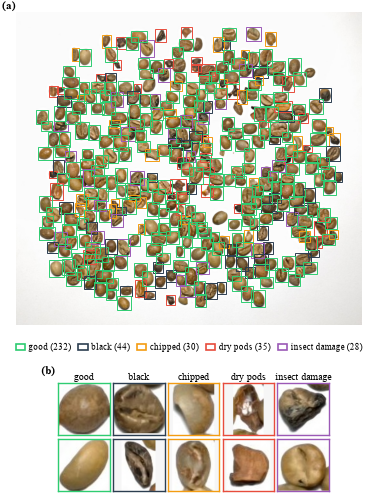

In [7]:
def plot_fig_data():
    photo = load_rgb(chosen['image_path'])
    H, W = photo.shape[:2]
    boxes = load_yolo_annotations(chosen['label_path'])

    if ZOOM == 'auto':
        b = np.array([box[1:] for box in boxes])
        x0f = max(0.0, (b[:, 0] - b[:, 2] / 2).min() - ZOOM_MARGIN)
        y0f = max(0.0, (b[:, 1] - b[:, 3] / 2).min() - ZOOM_MARGIN)
        x1f = min(1.0, (b[:, 0] + b[:, 2] / 2).max() + ZOOM_MARGIN)
        y1f = min(1.0, (b[:, 1] + b[:, 3] / 2).max() + ZOOM_MARGIN)
    else:
        x0f, y0f, x1f, y1f = ZOOM or (0.0, 0.0, 1.0, 1.0)
    X0, Y0, X1, Y1 = int(x0f * W), int(y0f * H), int(x1f * W), int(y1f * H)
    view = photo[Y0:Y1, X0:X1]
    # Perkecil untuk tampilan (cukup tajam di 300 dpi untuk lebar 3,5 in).
    scale = min(1.0, 2400 / view.shape[1])
    view = cv2.resize(view, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
    aspect = view.shape[0] / view.shape[1]

    photo_h = COL_W * aspect
    crops_h = 0.62 * CROPS_PER_CLASS + 0.2
    fig = plt.figure(figsize=(COL_W, photo_h + 0.35 + crops_h))
    top, bottom = fig.subfigures(2, 1, height_ratios=[photo_h + 0.35, crops_h], hspace=0.02)

    # (a) foto + bbox
    ax = top.add_axes([0, 0.1, 1, 0.9])
    ax.imshow(view)
    ax.set_axis_off()
    present = Counter()
    for cls, xc, yc, w, h in boxes:
        # Persamaan (1) paper: normalisasi -> piksel, dengan clipping ke batas citra.
        x1, x2 = max(0.0, (xc - w / 2) * W), min(W, (xc + w / 2) * W)
        y1, y2 = max(0.0, (yc - h / 2) * H), min(H, (yc + h / 2) * H)
        if x2 < X0 or x1 > X1 or y2 < Y0 or y1 > Y1:
            continue
        name = CLASS_NAMES[cls]
        present[name] += 1
        ax.add_patch(Rectangle(((x1 - X0) * scale, (y1 - Y0) * scale), (x2 - x1) * scale, (y2 - y1) * scale,
                               fill=False, edgecolor=CLASS_COLORS[name], linewidth=BOX_LINEWIDTH))
    ax.set_xlim(0, view.shape[1])
    ax.set_ylim(view.shape[0], 0)
    panel_label(ax, '(a)', x=0.0, y=1.0)
    handles = [Patch(facecolor='none', edgecolor=CLASS_COLORS[n], linewidth=1.2,
                     label=f'{CLASS_LABELS[n]} ({present[n]})') for n in CLASS_NAMES]
    top.legend(handles=handles, loc='lower center', ncol=5, handlelength=1.0, handletextpad=0.4,
               columnspacing=0.8, fontsize=6.5, bbox_to_anchor=(0.5, 0.0))

    # (b) strip crop: kolom = kelas, baris = sampel
    axes = bottom.subplots(CROPS_PER_CLASS, len(CLASS_NAMES), gridspec_kw={'wspace': 0.06, 'hspace': 0.06})
    axes = np.atleast_2d(axes)
    for col, name in enumerate(CLASS_NAMES):
        for row, path in enumerate(sample_crops[name]):
            a = axes[row, col]
            a.imshow(letterbox(load_rgb(path), CROP_TILE_PX))
            a.set_xticks([]); a.set_yticks([]); a.grid(False)
            for spine in a.spines.values():
                spine.set_visible(True); spine.set_color(CLASS_COLORS[name]); spine.set_linewidth(1.0)
            if row == 0:
                a.set_title(CLASS_LABELS[name], fontsize=7, pad=2)
    panel_label(axes[0, 0], '(b)', x=-0.05, y=1.12)
    return fig


fig = plot_fig_data()
save_paper(fig, 'fig_data', formats=('png', 'pdf'))
plt.show()

## Fig. 3 — Learning curves (`fig_curves.pdf`)

(a) Loss cross-entropy train (garis solid) dan validasi (garis putus) per epoch;
(b) akurasi validasi per epoch, dengan marker di epoch checkpoint terbaik
(`best_epoch`, 1-indexed, terverifikasi = `val_acc[best_epoch-1]`).

Disimpan: fig_curves.pdf, fig_curves.png


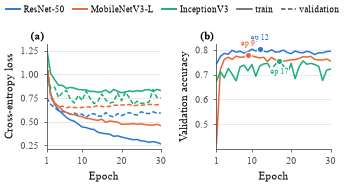

In [8]:
def plot_fig_curves():
    fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(COL_W, 1.75))
    for m in MODELS:
        h, color = histories[m], MODEL_COLORS[m]
        epochs = np.arange(1, len(h['train_loss']) + 1)
        ax_loss.plot(epochs, h['train_loss'], color=color, lw=1.1, ls='-')
        ax_loss.plot(epochs, h['val_loss'], color=color, lw=1.1, ls=(0, (3, 1.5)))
        ax_acc.plot(epochs, h['val_acc'], color=color, lw=1.1)
        best = int(h['best_epoch'])
        assert abs(h['val_acc'][best - 1] - h['best_val_acc']) < 1e-9
        ax_acc.plot(best, h['val_acc'][best - 1], marker='o', ms=4.5, mfc=color, mec='white', mew=0.8, zorder=5)
        dy = -5 if m == 'inceptionv3' else 5  # InceptionV3 di bawah agar tidak menimpa kurva lain
        ax_acc.annotate(f'ep {best}', (best, h['val_acc'][best - 1]), xytext=(0, dy), textcoords='offset points',
                        ha='center', va='bottom' if dy > 0 else 'top', fontsize=5.5, color=color,
                        bbox={'boxstyle': 'square,pad=0.1', 'facecolor': 'white', 'edgecolor': 'none'}, zorder=6)

    for ax in (ax_loss, ax_acc):
        ax.set_xlabel('Epoch')
        ax.set_xlim(1, 30)
        ax.set_xticks([1, 10, 20, 30])
    ax_loss.set_ylabel('Cross-entropy loss')
    ax_acc.set_ylabel('Validation accuracy')
    panel_label(ax_loss, '(a)')
    panel_label(ax_acc, '(b)')

    model_handles = [Line2D([], [], color=MODEL_COLORS[m], lw=1.4, label=MODEL_LABELS[m]) for m in MODELS]
    style_handles = [Line2D([], [], color=INK_2, lw=1.1, ls='-', label='train'),
                     Line2D([], [], color=INK_2, lw=1.1, ls=(0, (3, 1.5)), label='validation')]
    fig.legend(handles=model_handles + style_handles, loc='lower center', ncol=5, bbox_to_anchor=(0.5, 0.98),
               handlelength=1.6, columnspacing=0.9, handletextpad=0.4, fontsize=6.5)
    fig.tight_layout(w_pad=1.2)
    return fig


fig = plot_fig_curves()
save_paper(fig, 'fig_curves')
plt.show()

## Fig. 4 — F1 per kelas (`fig_perclass_f1.pdf`)

Data sama dengan bagian bawah Tabel II. Sumbu y dimulai dari `F1_YMIN` (default
0,5 sesuai permintaan placeholder). Karena sumbu tidak mulai dari nol, panjang
bar **tidak proporsional** terhadap nilai — itu sebabnya nilai ditulis di atas
tiap bar. Set `F1_YMIN = 0` bila reviewer mempermasalahkannya.

Disimpan: fig_perclass_f1.pdf, fig_perclass_f1.png


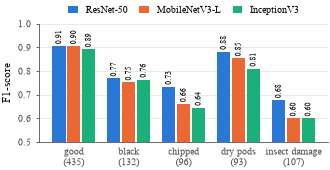

model,resnet50,mobilenetv3,inceptionv3
kelas,,,
good,0.906,0.905,0.892
black,0.769,0.752,0.764
chipped,0.734,0.660,0.645
dry_pods,0.882,0.854,0.810
insect_damage,0.677,0.600,0.600


In [9]:
F1_YMIN = 0.5
SHOW_VALUES = True


def plot_fig_perclass():
    table = per_class.pivot(index='kelas', columns='model', values='f1').loc[CLASS_NAMES, MODELS]
    support = per_class.drop_duplicates('kelas').set_index('kelas')['support']
    fig, ax = plt.subplots(figsize=(COL_W, 1.9))
    x = np.arange(len(CLASS_NAMES))
    width = 0.27
    for i, m in enumerate(MODELS):
        pos = x + (i - 1) * width
        ax.bar(pos, table[m] - F1_YMIN, width=width - 0.03, bottom=F1_YMIN, color=MODEL_COLORS[m],
               label=MODEL_LABELS[m], linewidth=0)
        if SHOW_VALUES:
            for xp, v in zip(pos, table[m]):
                ax.text(xp, v + 0.008, f'{v:.2f}', ha='center', va='bottom', rotation=90, fontsize=5.5, color=INK)
    ax.set_xticks(x, [f'{CLASS_LABELS[c]}\n({support[c]})' for c in CLASS_NAMES])
    ax.tick_params(axis='x', length=0)
    ax.set_ylim(F1_YMIN, 1.0)
    ax.set_ylabel('F1-score')
    ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=3, handlelength=1.0, columnspacing=1.2)
    fig.tight_layout()
    return fig, table


fig, f1_table = plot_fig_perclass()
save_paper(fig, 'fig_perclass_f1')
plt.show()
f1_table.round(3)

## Fig. 5 — Confusion matrix (`fig_confusion.pdf`)

Dihitung ulang dari prediksi test **dengan TTA D4**, dinormalisasi per baris
(baris = kelas sebenarnya). Sel `I→G` (insect damage diprediksi good, sumber
utama miss rate) diberi bingkai merah. Satu colorbar bersama untuk ketiga
matriks.

Disimpan: fig_confusion.pdf, fig_confusion.png


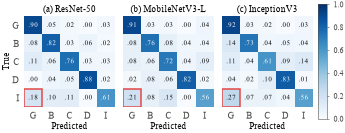

In [10]:
CM_FONTSIZE = 5.0
HIGHLIGHT = ('insect_damage', 'good')  # (true, pred)


def plot_fig_confusion():
    fig, axes = plt.subplots(1, 3, figsize=(COL_W, 1.55), layout='constrained')
    abbr = [CLASS_ABBR[c] for c in CLASS_NAMES]
    for k, (ax, m) in enumerate(zip(axes, MODELS)):
        cm = confusion_matrix(preds[m]['y_true'], preds[m]['y_pred'], labels=range(NUM_CLASSES))
        norm = cm / cm.sum(axis=1, keepdims=True)
        im = ax.imshow(norm, cmap='Blues', vmin=0, vmax=1)
        for i in range(NUM_CLASSES):
            for j in range(NUM_CLASSES):
                v = norm[i, j]
                ax.text(j, i, f'{v:.2f}'.lstrip('0') if v < 1 else '1.0', ha='center', va='center',
                        fontsize=CM_FONTSIZE, color='white' if v > 0.55 else INK)
        ti, pj = CLASS_NAMES.index(HIGHLIGHT[0]), CLASS_NAMES.index(HIGHLIGHT[1])
        ax.add_patch(Rectangle((pj - 0.5, ti - 0.5), 1, 1, fill=False, edgecolor='#e34948', linewidth=1.1))
        ax.set_xticks(range(NUM_CLASSES), abbr)
        ax.set_yticks(range(NUM_CLASSES), abbr if k == 0 else [])
        ax.tick_params(length=0, labelsize=6.5)
        ax.grid(False)
        for spine in ax.spines.values():
            spine.set_visible(False)
        ax.set_title(f'({"abc"[k]}) {MODEL_LABELS[m]}', fontsize=6.5, pad=3)
        ax.set_xlabel('Predicted', fontsize=6.5, labelpad=1)
        if k == 0:
            ax.set_ylabel('True', fontsize=6.5, labelpad=1)
    cbar = fig.colorbar(im, ax=axes, shrink=0.78, aspect=14, pad=0.02)
    cbar.ax.tick_params(labelsize=5.5, length=1.5, width=0.4)
    cbar.outline.set_linewidth(0.4)
    return fig


fig = plot_fig_confusion()
save_paper(fig, 'fig_confusion')
plt.show()

## Fig. 6 — Efek TTA (`fig_tta.pdf`)

Test set, tanpa TTA vs D4. Sumber: `tta_screening.csv` (sama dengan Tabel III
baris *Without TTA* dan teks bagian III-B).

Disimpan: fig_tta.pdf, fig_tta.png


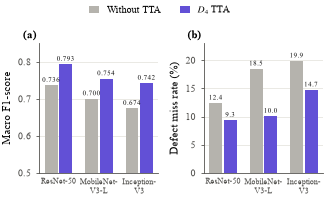

f1        miss_rate        insect_to_good     
tta             d4   none        d4   none             d4 none
model                                                         
inceptionv3  0.742  0.674     0.147  0.199             29   38
mobilenetv3  0.754  0.700     0.100  0.185             22   36
resnet50     0.793  0.736     0.093  0.124             19   24

In [11]:
TTA_COLORS = {'none': NEUTRAL, 'd4': '#6250d6'}
TTA_LABELS = {'none': 'Without TTA', 'd4': '$D_4$ TTA'}


def plot_fig_tta():
    test = tta[(tta['split'] == 'test') & (tta['tta'].isin(['none', 'd4']))].set_index(['model', 'tta'])
    fig, (ax_f1, ax_mr) = plt.subplots(1, 2, figsize=(COL_W, 1.9))
    short = {'resnet50': 'ResNet-50', 'mobilenetv3': 'MobileNet-\nV3-L', 'inceptionv3': 'Inception-\nV3'}
    x = np.arange(len(MODELS))
    width = 0.36
    panels = [(ax_f1, 'f1', 'Macro F1-score', 1.0, '{:.3f}', (0.5, 0.85)),
              (ax_mr, 'miss_rate', 'Defect miss rate (%)', 100.0, '{:.1f}', (0, 23))]
    for ax, col, ylabel, mult, fmt, ylim in panels:
        for i, mode in enumerate(['none', 'd4']):
            values = [test.loc[(m, mode), col] * mult for m in MODELS]
            pos = x + (i - 0.5) * width
            ax.bar(pos, np.array(values) - ylim[0], bottom=ylim[0], width=width - 0.04,
                   color=TTA_COLORS[mode], label=TTA_LABELS[mode], linewidth=0)
            for xp, v in zip(pos, values):
                ax.text(xp, v + (ylim[1] - ylim[0]) * 0.015, fmt.format(v), ha='center', va='bottom',
                        fontsize=5.3, color=INK)
        ax.set_xticks(x, [short[m] for m in MODELS], fontsize=6)
        ax.tick_params(axis='x', length=0)
        ax.set_ylim(*ylim)
        ax.set_ylabel(ylabel)
    panel_label(ax_f1, '(a)')
    panel_label(ax_mr, '(b)')
    handles, labels = ax_f1.get_legend_handles_labels()
    fig.legend(handles, labels, loc='lower center', ncol=2, bbox_to_anchor=(0.5, 0.97), handlelength=1.0)
    fig.tight_layout(w_pad=1.0)
    return fig, test


fig, tta_test = plot_fig_tta()
save_paper(fig, 'fig_tta')
plt.show()
tta_test[['f1', 'miss_rate', 'insect_to_good']].unstack('tta').round(3)

## Fig. 7 — Efisiensi vs performa (`fig_tradeoff.pdf`)

Sumbu x = ukuran model (MB) atau latensi 8 view (ms) — pilih lewat `TRADEOFF_X`.
Luas bubble sebanding jumlah parameter. Caption paper menyebut *model size*,
jadi default `'size'`.

Disimpan: fig_tradeoff.pdf, fig_tradeoff.png


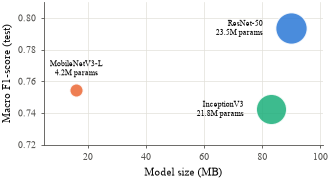

,params_total,model_size_mb,flops,inference_time_ms,inference_time_ms_tta,f1
model,,,,,,
resnet50,23518277,89.715,4087146496,4.6064,37.870067,0.793337
mobilenetv3,4208437,16.054,215316160,5.0068,40.293363,0.754205
inceptionv3,21795813,83.144,5711178336,9.7693,75.021346,0.742243


In [12]:
TRADEOFF_X = 'size'  # 'size' atau 'latency'


def plot_fig_tradeoff():
    xcol, xlabel = {'size': ('model_size_mb', 'Model size (MB)'),
                    'latency': ('inference_time_ms_tta', 'GPU latency, 8 views (ms)')}[TRADEOFF_X]
    fig, ax = plt.subplots(figsize=(COL_W, 2.0))
    params_m = efficiency['params_total'] / 1e6
    for m in MODELS:
        xv, yv = efficiency.loc[m, xcol], efficiency.loc[m, 'f1']
        ax.scatter(xv, yv, s=params_m[m] * 22, color=MODEL_COLORS[m], alpha=0.85, edgecolor='white', linewidth=1.0, zorder=3)
        # Label di kiri bubble besar, di atas bubble kecil (MobileNetV3) agar tidak terpotong.
        offset, ha, va = ((0, 9), 'center', 'bottom') if m == 'mobilenetv3' else ((-20, 0), 'right', 'center')
        ax.annotate(f'{MODEL_LABELS[m]}\n{params_m[m]:.1f}M params', (xv, yv), xytext=offset,
                    textcoords='offset points', ha=ha, va=va, fontsize=6, color=INK)
    xs = efficiency.loc[MODELS, xcol]
    pad = (xs.max() - xs.min()) * 0.15
    ax.set_xlim(max(0, xs.min() - pad), xs.max() + pad)
    ax.set_ylim(0.72, 0.81)
    ax.set_xlabel(xlabel)
    ax.set_ylabel('Macro F1-score (test)')
    ax.grid(True, axis='both')
    fig.tight_layout()
    return fig


fig = plot_fig_tradeoff()
save_paper(fig, 'fig_tradeoff')
plt.show()
efficiency.loc[MODELS, ['params_total', 'model_size_mb', 'flops', 'inference_time_ms', 'inference_time_ms_tta', 'f1']]

## Fig. 8 — Grad-CAM (`fig_gradcam.png`)

Grid 4 kolom: crop asli | ResNet-50 | MobileNetV3-L | InceptionV3.

- **Baris (a)**: 2 contoh prediksi **benar oleh ketiga model** (default: satu
  `black`, satu `insect_damage` berlubang besar).
- **Baris (b)**: 2 contoh `insect_damage` yang diprediksi **`good` oleh ketiga
  model**.

**Pemilihan** memakai prediksi **TTA D4** (`<m>_test_predictions.csv`), sama
dengan angka di paper; label di bawah heatmap = kelas TTA + confidence TTA.
Heatmap sendiri dihitung pada orientasi asli (satu citra) untuk kelas tersebut,
karena Grad-CAM menjelaskan satu pandangan.

"Lubang besar" vs "lubang kecil tunggal" **tidak bisa dipilih otomatis** —
lihat galeri kandidat di bawah, lalu isi `ROW_A` / `ROW_B` dengan nama berkas
pilihan. Lingkaran penanda lubang diisi manual di `HOLE_MARKS`.

In [13]:
import torch

from configs.cnn_config import CNN_CONFIG
from src.analysis.gradcam import GradCAMAnalyzer
from src.models.model_factory import get_model
from src.utils.io import load_checkpoint

cam_models = {}
for m in MODELS:
    checkpoint = sorted((MODELS_DIR / m).glob('*.pt'))[-1]
    model = get_model(m, num_classes=NUM_CLASSES, pretrained=False)
    load_checkpoint(model, checkpoint, map_location=DEVICE)
    cam_models[m] = model
    print(f'{m}: {checkpoint.name}')
analyzers = {m: GradCAMAnalyzer(cam_models[m], m, device=DEVICE) for m in MODELS}

# Satu tabel lebar: satu baris per biji, kolom prediksi/confidence tiap model.
joined = preds[MODELS[0]][['path', 'true_label']].copy()
for m in MODELS:
    joined[f'pred_{m}'] = preds[m]['pred_label'].values
    joined[f'conf_{m}'] = preds[m]['confidence'].values
    joined[f'pgood_{m}'] = preds[m]['prob_good'].values
    assert (preds[m]['path'].values == joined['path'].values).all()
joined['name'] = joined['path'].map(lambda p: Path(p).name)
joined['all_correct'] = np.all([joined[f'pred_{m}'] == joined['true_label'] for m in MODELS], axis=0)
joined['all_good'] = np.all([joined[f'pred_{m}'] == 'good' for m in MODELS], axis=0)
joined['min_conf'] = joined[[f'conf_{m}' for m in MODELS]].min(axis=1)
joined['mean_pgood'] = joined[[f'pgood_{m}' for m in MODELS]].mean(axis=1)

cand_black = joined[(joined.true_label == 'black') & joined.all_correct].sort_values('min_conf', ascending=False)
cand_insect_ok = joined[(joined.true_label == 'insect_damage') & joined.all_correct].sort_values('min_conf', ascending=False)
cand_insect_miss = joined[(joined.true_label == 'insect_damage') & joined.all_good].sort_values('mean_pgood', ascending=False)
print(f'black benar di 3 model: {len(cand_black)} | insect benar di 3 model: {len(cand_insect_ok)} | '
      f'insect -> good di 3 model: {len(cand_insect_miss)}')

resnet50: resnet50_best_epoch12_acc0.80.pt
mobilenetv3: mobilenetv3_best_epoch9_acc0.78.pt
inceptionv3: inceptionv3_best_epoch17_acc0.76.pt
black benar di 3 model: 88 | insect benar di 3 model: 42 | insect -> good di 3 model: 10


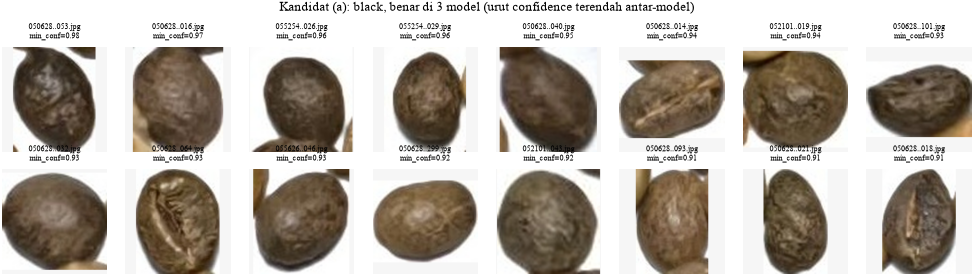

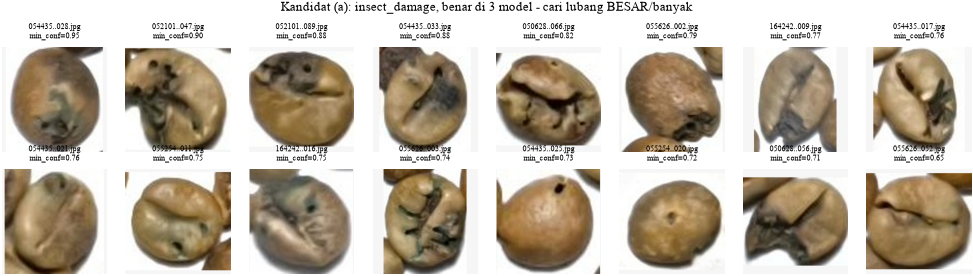

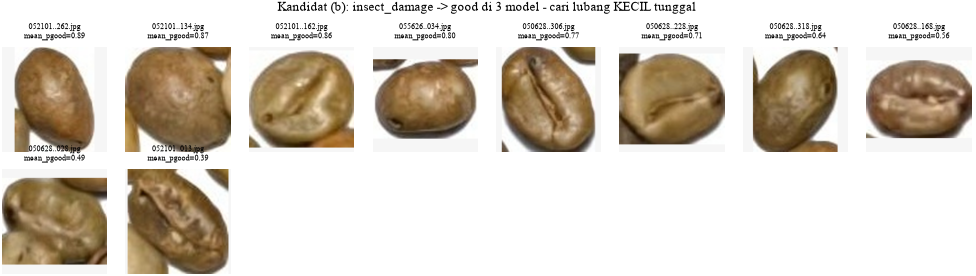

In [14]:
def show_candidates(frame: pd.DataFrame, title: str, n: int = 16, ncols: int = 8, value: str = 'min_conf'):
    # Galeri kandidat (crop asli, tanpa resize paksa) untuk dipilih manual.
    rows = frame.head(n)
    nrows = int(np.ceil(len(rows) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 1.25, nrows * 1.45), squeeze=False)
    for ax in axes.flat:
        ax.set_axis_off()
    for ax, (_, r) in zip(axes.flat, rows.iterrows()):
        ax.imshow(letterbox(load_rgb(Path(r['path'])), 200))
        short = r['name'].split('_jpg')[0][-6:] + '..' + r['name'].split('_bean_')[-1]
        ax.set_title(f"{short}\n{value}={r[value]:.2f}", fontsize=6)
    fig.suptitle(title, fontsize=9)
    fig.tight_layout()
    plt.show()


show_candidates(cand_black, 'Kandidat (a): black, benar di 3 model (urut confidence terendah antar-model)')
show_candidates(cand_insect_ok, 'Kandidat (a): insect_damage, benar di 3 model - cari lubang BESAR/banyak')
show_candidates(cand_insect_miss, 'Kandidat (b): insect_damage -> good di 3 model - cari lubang KECIL tunggal', value='mean_pgood')

**Pilih sampel.** Isi nama berkas lengkap (kolom `name`; cetak dengan
`cand_insect_miss[['name', 'mean_pgood']]`). Bila `None`, dipakai kandidat
teratas otomatis.

`HOLE_MARKS` = lingkaran penanda lubang pada crop asli, dalam **fraksi**
lebar/tinggi crop: `{'<nama>.jpg': [(cx, cy, r), ...]}`; mis. `(0.42, 0.55, 0.12)`.

In [15]:
ROW_A = None   # mis. ['<black>.jpg', '<insect lubang besar>.jpg']
ROW_B = None   # mis. ['<insect lubang kecil 1>.jpg', '<insect lubang kecil 2>.jpg']
HOLE_MARKS = {}

if ROW_A is None:
    ROW_A = [cand_black['name'].iloc[0], cand_insect_ok['name'].iloc[0]]
if ROW_B is None:
    ROW_B = list(cand_insect_miss['name'].iloc[:2])
print('ROW_A =', ROW_A)
print('ROW_B =', ROW_B)

ROW_A = ['IMG_20260814_050628_jpg.rf.11cdf4a01bf3a0e9a2e46669b04ad17e_bean_053.jpg', 'IMG_20260814_054435_jpg.rf.f90eb76e70dc268abe746e7f0f8d27cc_bean_028.jpg']
ROW_B = ['IMG_20260814_052101_jpg.rf.93627dc0e6a1bdbf36614caa492066fb_bean_262.jpg', 'IMG_20260814_052101_jpg.rf.93627dc0e6a1bdbf36614caa492066fb_bean_134.jpg']


Disimpan: fig_gradcam.png, fig_gradcam.pdf


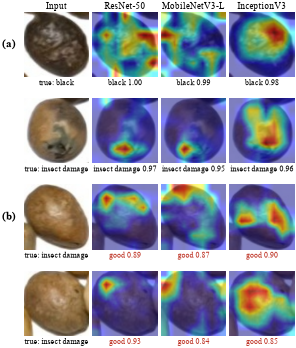

In [16]:
def plot_fig_gradcam(row_a, row_b, hole_marks):
    by_name = joined.set_index('name')
    samples = [('(a)', n) for n in row_a] + [('(b)', n) for n in row_b]
    ncols = 1 + len(MODELS)
    cell = COL_W / ncols
    fig, axes = plt.subplots(len(samples), ncols, figsize=(COL_W, cell * len(samples) * 1.16 + 0.15),
                             gridspec_kw={'wspace': 0.04, 'hspace': 0.32})
    for r, (group, name) in enumerate(samples):
        info = by_name.loc[name]
        path = Path(info['path'])
        results = {}
        for m in MODELS:
            target = CLASS_NAMES.index(info[f'pred_{m}'])  # kelas keputusan TTA
            results[m] = analyzers[m].explain(path, target_class=target)

        ax = axes[r, 0]
        rgb = results[MODELS[0]]['rgb']
        ax.imshow(rgb)
        for cx, cy, rad in hole_marks.get(name, []):
            h, w = rgb.shape[:2]
            ax.add_patch(Circle((cx * w, cy * h), rad * w, fill=False, edgecolor='#e34948', linewidth=1.0))
        ax.set_xlabel(f"true: {CLASS_LABELS[info['true_label']]}", fontsize=6, labelpad=1.5)
        if r == 0:
            ax.set_title('Input', fontsize=6.5, pad=2)
        if r == 0 or samples[r - 1][0] != group:
            ax.text(-0.12, 0.5, group, transform=ax.transAxes, ha='right', va='center', fontweight='bold')

        for c, m in enumerate(MODELS, start=1):
            ax = axes[r, c]
            ax.imshow(results[m]['overlay'])
            pred, conf = info[f'pred_{m}'], info[f'conf_{m}']
            wrong = pred != info['true_label']
            ax.set_xlabel(f'{CLASS_LABELS[pred]} {conf:.2f}', fontsize=6, labelpad=1.5,
                          color='#c0392b' if wrong else INK)
            if r == 0:
                ax.set_title(MODEL_LABELS[m], fontsize=6.5, pad=2)
        for ax in axes[r]:
            ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
            for spine in ax.spines.values():
                spine.set_visible(False)
    return fig


fig = plot_fig_gradcam(ROW_A, ROW_B, HOLE_MARKS)
save_paper(fig, 'fig_gradcam', formats=('png', 'pdf'))
plt.show()

## Fig. 9 — Confidence dan ruang fitur (`fig_confidence.pdf`)

(a) Histogram confidence prediksi benar vs salah (`CONF_MODEL`, test, TTA D4),
dalam persen dari masing-masing kelompok (jumlah benar ≫ salah, jadi hitungan
mentah akan menenggelamkan kelompok salah). Garis putus = rata-rata.
(b) Proyeksi 2D fitur backbone beku (vektor sebelum head, dari
`<m>_test_features.npz`) diwarnai per kelas, dengan marker berbeda per kelas.
`PROJECTION = 'tsne'` (default) atau `'pca'`.

> t-SNE hanya alat lihat; jarak antar-klaster tidak bisa dibaca kuantitatif.
> Angka pemisahannya ada di silhouette (`feature_separation.csv`), yang juga
> dikutip di teks paper.

In [17]:
from sklearn.decomposition import PCA

from src.analysis.feature_visualization import compute_tsne, load_features

CONF_MODEL = 'resnet50'
PROJECTION = 'tsne'  # 'tsne' atau 'pca'

features, feat_labels = load_features(ANALYSIS_DIR / f'{CONF_MODEL}_test_features.npz')
if PROJECTION == 'tsne':
    embedding = compute_tsne(features, random_seed=RANDOM_SEED)
else:
    embedding = PCA(n_components=2, random_state=RANDOM_SEED).fit_transform(features)
silhouette = pd.read_csv(ANALYSIS_DIR / 'feature_separation.csv').set_index('model').loc[CONF_MODEL, 'silhouette_score']
print(features.shape, 'silhouette =', silhouette)

(863, 2048) silhouette = -0.015


Disimpan: fig_confidence.pdf, fig_confidence.png


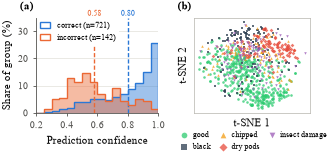

In [18]:
CONF_COLORS = {'correct': '#2a78d6', 'incorrect': '#eb6834'}


def plot_fig_confidence():
    frame = preds[CONF_MODEL]
    fig, (ax_h, ax_p) = plt.subplots(1, 2, figsize=(COL_W, 1.85), gridspec_kw={'width_ratios': [1.05, 1]})

    bins = np.linspace(0.2, 1.0, 17)
    for key, mask in (('correct', frame['correct']), ('incorrect', ~frame['correct'])):
        conf = frame.loc[mask, 'confidence']
        weights = np.full(len(conf), 100.0 / len(conf))
        ax_h.hist(conf, bins=bins, weights=weights, color=CONF_COLORS[key], alpha=0.45, linewidth=0)
        ax_h.hist(conf, bins=bins, weights=weights, histtype='step', color=CONF_COLORS[key], linewidth=1.0,
                  label=f'{key} (n={len(conf)})')
        mean = conf.mean()
        ax_h.axvline(mean, color=CONF_COLORS[key], linestyle=(0, (3, 1.5)), linewidth=1.0)
    # Label rata-rata ditulis setelah semua histogram agar posisi y = puncak sumbu final.
    ymax = ax_h.get_ylim()[1] * 1.3  # ruang kosong di atas untuk legenda
    ax_h.set_ylim(0, ymax)
    for key, mask in (('correct', frame['correct']), ('incorrect', ~frame['correct'])):
        mean = frame.loc[mask, 'confidence'].mean()
        ax_h.text(mean, ymax * 1.0, f'{mean:.2f}', ha='center', va='bottom', fontsize=6, color=CONF_COLORS[key])
    ax_h.set_xlabel('Prediction confidence')
    ax_h.set_ylabel('Share of group (%)')
    ax_h.set_xlim(0.2, 1.0)
    legend = ax_h.legend(loc='upper left', fontsize=6, handlelength=1.2, borderaxespad=0.1,
                         frameon=True, facecolor='white', edgecolor='none', framealpha=1.0)
    legend.set_zorder(10)
    panel_label(ax_h, '(a)', y=1.06)

    for idx, name in enumerate(CLASS_NAMES):
        sel = feat_labels == idx
        ax_p.scatter(embedding[sel, 0], embedding[sel, 1], s=3.5, marker=CLASS_MARKERS[name],
                     color=CLASS_COLORS[name], alpha=0.75, linewidths=0, label=CLASS_LABELS[name])
    ax_p.set_xticks([]); ax_p.set_yticks([]); ax_p.grid(False)
    for spine in ax_p.spines.values():
        spine.set_visible(True); spine.set_linewidth(0.5); spine.set_color(NEUTRAL)
    ax_p.set_xlabel('t-SNE 1' if PROJECTION == 'tsne' else 'PC 1')
    ax_p.set_ylabel('t-SNE 2' if PROJECTION == 'tsne' else 'PC 2')
    panel_label(ax_p, '(b)', y=1.06)
    ax_p.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=3, fontsize=5.5, markerscale=2.2,
                handletextpad=0.1, columnspacing=0.6)
    fig.tight_layout(w_pad=1.0)
    return fig


fig = plot_fig_confidence()
save_paper(fig, 'fig_confidence')
plt.show()

## Ringkasan berkas

Untuk LaTeX: `\includegraphics[width=\columnwidth]{fig_curves.pdf}`. Pakai PDF
untuk grafik (vektor) dan PNG untuk figur bercitra (Fig. 2 & 8); versi PDF
Fig. 2/8 juga tersedia, tetapi citra di dalamnya tetap raster.

In [19]:
pd.DataFrame(
    [{'file': p.name, 'size (KB)': round(p.stat().st_size / 1024, 1)} for p in sorted(PAPER_DIR.iterdir())]
)

,file,size (KB)
0,fig_confidence.pdf,59.7
1,fig_confidence.png,96.2
2,fig_confusion.pdf,36.6
3,fig_confusion.png,74.9
4,fig_curves.pdf,44.3
5,fig_curves.png,95.2
6,fig_data.pdf,1383.8
7,fig_data.png,1409.3
8,fig_gradcam.pdf,670.5
9,fig_gradcam.png,779.8
